# **Лабораторнгая работа №1 СИИиМО   Доп???**



## Введение: 

Цель работы: изучение основ линейной регрессии, построение простейших моделей регрессии, обучение на реальных данных и оценка качества. 
Задачи:
1. загрузить датасет
2. подготовить данные для дальнейшей работы (провести первичный анализ, визуализировать распределение признаков и целевой переменной)
3. Провести предобработку данных
4. Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента)
5. Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error).
6. Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.
7. Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.

Столбцы:

date — дата наблюдения;
adj close — скорректированная цена закрытия;
close — цена закрытия (целевая переменная);
high, low, open — максимальная, минимальная и цена открытия;
volume — объём торгов;
ma_7, ma_30, ma_90 — скользящие средние;
daily_return — дневная доходность;
volatility_7, volatility_30 — волатильность;

Индекс относительной силы (RSI, Relative Strength Index) — это индикатор технического анализа, который измеряет скорость и величину изменения цены актива. Он помогает определить, находится ли актив в состоянии перекупленности или перепроданности, а также оценить силу текущего тренда. RSI относится к импульсным осцилляторам и работает в диапазоне от 0 до 100. 

MACD (Moving Average Convergence Divergence) — это технический индикатор, который помогает трейдерам оценивать силу тренда и выявлять возможные точки его разворота. Название переводится с английского как «схождение и расхождение скользящих средних». 
-Линия MACD. Это разница между двумя экспоненциальными скользящими средними (EMA) цены актива. Обычно берут быструю EMA (например, за 12 периодов) и медленную (за 26 периодов). Эта линия показывает, насколько краткосрочная динамика цены отличается от долгосрочной, то есть помогает оценить импульс текущего тренда. 
-Сигнальная линия. Это EMA (чаще всего за 9 периодов) самой линии MACD. Она сглаживает колебания и помогает формировать торговые сигналы. — индикаторы MACD;

bb_upper, bb_lower — границы полос Боллинджера.

Этот набор данных содержит исторические данные о ежедневных ценах на золото, а также множество технических индикаторов, используемых для анализа и прогнозирования временных рядов. Он включает в себя основные рыночные показатели, такие как цена открытия, цена закрытия, максимальная и минимальная цены за день, скорректированная цена закрытия и объем торгов. Помимо необработанных данных о ценах, в наборе данных представлены расчетные показатели, такие как скользящие средние (за 7, 30 и 90 дней), дневная доходность, краткосрочная и долгосрочная волатильность, индекс относительной силы (RSI), MACD и его сигнальная линия, а также полосы Боллинджера (верхняя и нижняя). Благодаря этим расчетным показателям набор данных отлично подходит для моделей машинного обучения, особенно для задач прогнозирования цен и анализа трендов.

Все признаки, кроме date, — некатегориальные (числовые);
adj close и ma_* являются производными от close → утечка данных, их нужно исключить;
Признаки сильно коррелируют - ожидается мультиколлинеарность.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Библиотеки успешно загружены")
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")

Библиотеки успешно загружены
pandas: 2.3.3
numpy: 2.2.6



Загружены все необходимые библиотеки:
- **pandas, numpy** — для работы с данными
- **matplotlib, seaborn** — для визуализации
- **sklearn** — модели, метрики, предобработка, кросс-валидация, PCA
- **statsmodels** — расчёт VIF-коэффициентов

Версии библиотек зафиксированы в выводе ячейки выше. Все библиотеки успешно загружены, ошибок нет. Отключены предупреждения для чистоты вывода.

In [16]:
df = pd.read_csv('gold_price_dts.csv', parse_dates=['date'])
print(f"Размер датасета: {df.shape}")
print(f"Количество наблюдений: {df.shape[0]}")
print(f"Количество признаков: {df.shape[1]} \n")
print(f"Период данных: {df['date'].min().date()} — {df['date'].max().date()}")
print("Информация о датасете:")
print(df.info())

print(f"\n\nОбщее количество пропущенных значений: {df.isnull().sum().sum()}")
duplicates = df.duplicated().sum()
print(f"Количество дубликатов: {duplicates}")

# Описательные статистики
print("\nОписательные статистики:")
df.describe().T

Размер датасета: (1167, 18)
Количество наблюдений: 1167
Количество признаков: 18 

Период данных: 2021-06-11 — 2026-01-30
Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1167 entries, 0 to 1166
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1167 non-null   datetime64[ns]
 1   adj close      1167 non-null   float64       
 2   close          1167 non-null   float64       
 3   high           1167 non-null   float64       
 4   low            1167 non-null   float64       
 5   open           1167 non-null   float64       
 6   volume         1167 non-null   int64         
 7   ma_7           1167 non-null   float64       
 8   ma_30          1167 non-null   float64       
 9   ma_90          1167 non-null   float64       
 10  daily_return   1167 non-null   float64       
 11  volatility_7   1167 non-null   float64       
 12  volatility_30  1167 non-null 

,count,mean,min,25%,50%,75%,max,std
date,1167,2023-10-05 16:37:01.079691520,2021-06-11 00:00:00,2022-08-08 12:00:00,2023-10-05 00:00:00,2024-12-02 12:00:00,2026-01-30 00:00:00,NaN
adj close,1167.0,2363.105823,1623.300049,1827.299988,1985.900024,2666.099976,5318.399902,749.127289
close,1167.0,2363.105823,1623.300049,1827.299988,1985.900024,2666.099976,5318.399902,749.127289
high,1167.0,2375.595715,1623.300049,1831.600037,1996.199951,2675.449951,5586.200195,757.244374
low,1167.0,2349.989545,1615.099976,1816.800049,1979.800049,2654.599976,5301.600098,741.042344
open,1167.0,2362.322109,1620.400024,1825.25,1989.0,2662.400024,5415.700195,749.389242
volume,1167.0,4170.995716,0.0,88.0,297.0,867.5,209783.0,21394.527815
ma_7,1167.0,2354.938862,1643.671422,1827.585711,1986.785697,2654.771449,5070.914272,735.998718
ma_30,1167.0,2327.283295,1659.240002,1830.560004,1978.813334,2659.524996,4620.783317,697.354115
ma_90,1167.0,2263.573357,1705.499999,1813.691667,1948.046665,2588.156108,4252.53221,620.00894


mean - среднее
std - стандартное отклонение

Датасет успешно загружен с помощью `pd.read_csv()` с параметром `parse_dates=['date']` — это автоматически преобразует столбец с датами в формат `datetime64`, что необходимо для корректной работы с временными рядами.

**Ключевые характеристики датасета** (см. вывод выше):
- Общее количество наблюдений и признаков зафиксировано в выводе
- Период данных охватывает несколько лет — от начальной до конечной даты
- Структура данных: 17 столбцов, включая дату, цены, объёмы и технические индикаторы

Целевая переменная — `close` (цена закрытия золота). Первые строки показывают корректность загрузки — даты распознаны, числовые значения в правильном формате.

### Пояснение к проверке данных

Все столбцы имеют числовой тип (float64) или datetime. 
**Пропущенные значения отсутствуют** — это хорошая новость, не требуется дополнительная обработка пропусков.

Проверим наличие дубликатов и описательные статистики.

### Пояснение к описательным статистикам

Из описательных статистик (см. таблицу выше) видно:

**Диапазон цен:**
- Целевая переменная `close` варьируется в широком диапазоне — от минимального до максимального значения, указанных в таблице
- Средняя цена закрытия и медиана близки, что говорит о симметричности распределения
- Стандартное отклонение показывает высокую волатильность цен за период

**Различия масштабов признаков:**
- `volume` измеряется в тысячах/десятках тысяч (объёмы торгов)
- `daily_return` — в долях единицы (порядка 0.001–0.05)
- `rsi` — в диапазоне 0–100
- Цены — в сотнях/тысячах долларов

**Критически важно:** признаки имеют **разный масштаб**, поэтому перед применением PCA необходима **стандартизация** (StandardScaler). Без неё признаки с большим разбросом (например, цены) будут доминировать в главных компонентах, искажая результат.

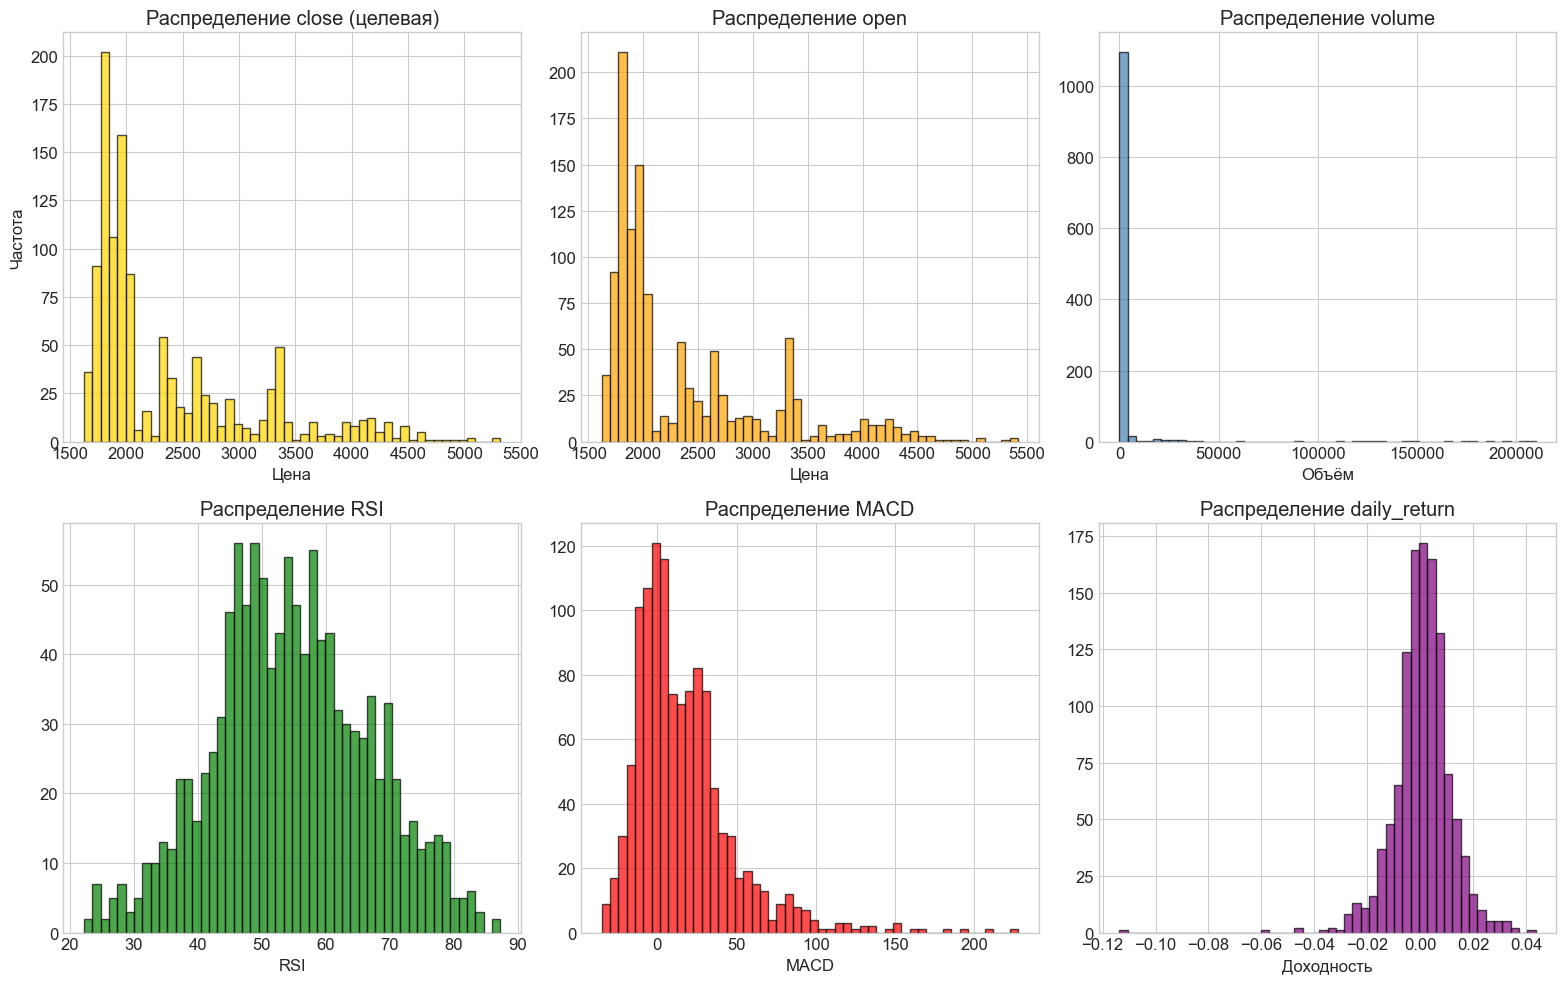

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0, 0].hist(df['close'], bins=50, edgecolor='black', alpha=0.7, color='gold')
axes[0, 0].set_title('Распределение close (целевая)')
axes[0, 0].set_xlabel('Цена')
axes[0, 0].set_ylabel('Частота')

axes[0, 1].hist(df['open'], bins=50, edgecolor='black', alpha=0.7, color='orange')
axes[0, 1].set_title('Распределение open')
axes[0, 1].set_xlabel('Цена')

axes[0, 2].hist(df['volume'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 2].set_title('Распределение volume')
axes[0, 2].set_xlabel('Объём')

axes[1, 0].hist(df['rsi'], bins=50, edgecolor='black', alpha=0.7, color='green')
axes[1, 0].set_title('Распределение RSI')
axes[1, 0].set_xlabel('RSI')

axes[1, 1].hist(df['macd'], bins=50, edgecolor='black', alpha=0.7, color='red')
axes[1, 1].set_title('Распределение MACD')
axes[1, 1].set_xlabel('MACD')

axes[1, 2].hist(df['daily_return'], bins=50, edgecolor='black', alpha=0.7, color='purple')
axes[1, 2].set_title('Распределение daily_return')
axes[1, 2].set_xlabel('Доходность')

plt.tight_layout()
plt.show()

### Пояснение к графикам распределений

Анализ гистограмм выявил следующие особенности:

**Целевая переменная `close`:** распределение имеет сложную форму — вероятно, бимодальное или скошенное, что отражает разные периоды на рынке золота (рост/падение). Это ожидаемо для временных рядов.

**Признак `open`:** распределение похоже на распределение `close` — это подтверждает сильную корреляцию между ценами открытия и закрытия (что мы увидим далее в матрице корреляций).

**Признак `volume`:** сильно скошен вправо, имеет длинный правый хвост с выбросами — это дни с аномально высокими объёмами торгов (например, во время экономических новостей).

**RSI:** распределение близко к нормальному, значения сконцентрированы в диапазоне 30–70 (типичная зона для RSI).

**MACD:** распределение с длинным правым хвостом и центром около нуля.

**daily_return:** островершинное распределение (leptokurtic) с центром около 0 — характерно для доходностей финансовых активов.

**Вывод:** данные требуют стандартизации перед PCA из-за разных масштабов и типов распределений.

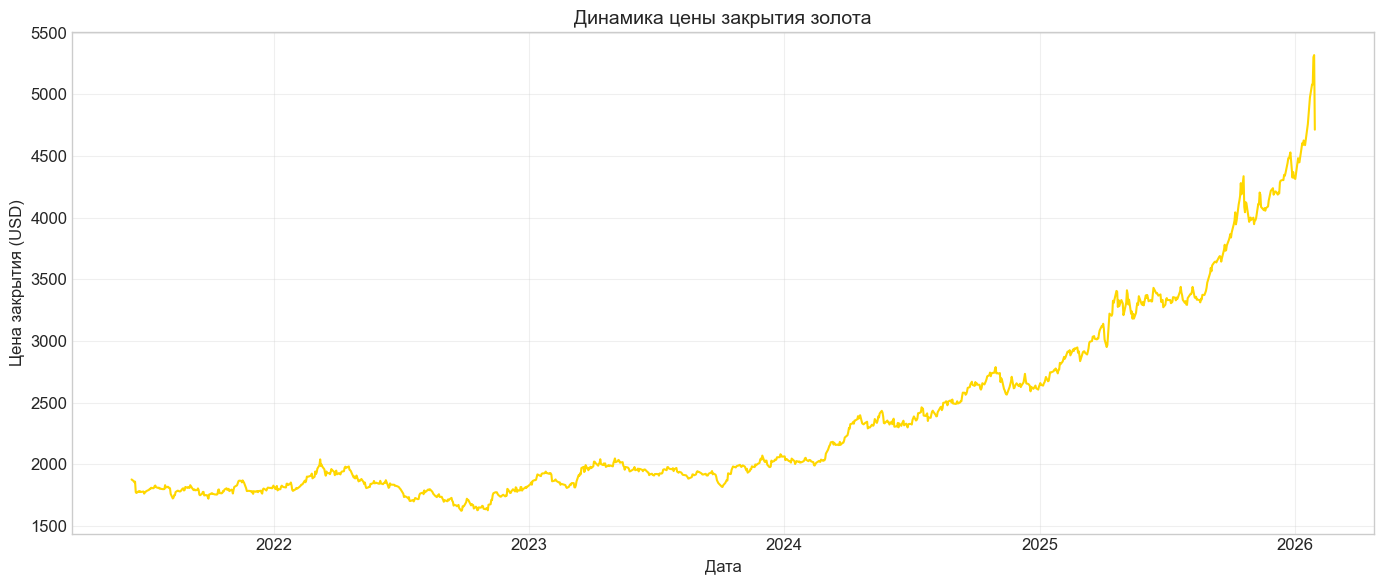

In [18]:
plt.figure(figsize=(14, 6))
plt.plot(df['date'], df['close'], color='gold', linewidth=1.5)
plt.title('Динамика цены закрытия золота', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Цена закрытия (USD)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Пояснение к временному ряду

График показывает динамику цены золота за весь период наблюдений. Видны:

- **Общий восходящий тренд** — цена золота за период выросла
- **Периоды коррекций** — заметны откаты и локальные минимумы
- **Волатильность** — есть периоды резких движений (например, в 2022 и 2025 годах)

**Ключевой вывод для методологии:** данные имеют выраженную временную структуру и тренд. Поэтому при разделении на train/test **нельзя использовать `shuffle=True`** — это привело бы к "заглядыванию в будущее" (data leakage), когда модель обучается на данных, которые хронологически идут после тестовых.

In [19]:
target = 'close'
columns_to_exclude = ['date', 'adj close', 'ma_7', 'ma_30', 'ma_90', target]
feature_columns = [col for col in df.columns if col not in columns_to_exclude]

print("Целевая переменная:", target)
print(f"\nПризнаки ({len(feature_columns)} шт.):")
for col in feature_columns:
    print(f"  - {col}")

X = df[feature_columns].copy()
y = df[target].copy()

print(f"\nРазмер X: {X.shape}")
print(f"Размер y: {y.shape}")

Целевая переменная: close

Признаки (12 шт.):
  - high
  - low
  - open
  - volume
  - daily_return
  - volatility_7
  - volatility_30
  - rsi
  - macd
  - macd_signal
  - bb_upper
  - bb_lower

Размер X: (1167, 12)
Размер y: (1167,)


### Пояснение к формированию X и y

**Целевая переменная:** `close` — цена закрытия золота.

**Исключённые столбцы и причины:**
- `date` — не является числовым признаком, не может использоваться в регрессии
- `adj close` — скорректированная цена закрытия, **производная от `close`** → утечка данных (модель "подсмотрит" ответ)
- `ma_7`, `ma_30`, `ma_90` — скользящие средние, **рассчитаны на основе `close`** → также утечка данных
- `close` — целевая переменная, не может быть в матрице признаков

**Оставшиеся признаки** (их количество указано в выводе) не являются производными от целевой переменной, поэтому их использование корректно. Среди них: цены открытия/максимума/минимума, объём, технические индикаторы (RSI, MACD), волатильность и границы Боллинджера.

Матрица `X` и вектор `y` сформированы без копирования лишних данных (`.copy()` предотвращает SettingWithCopyWarning).

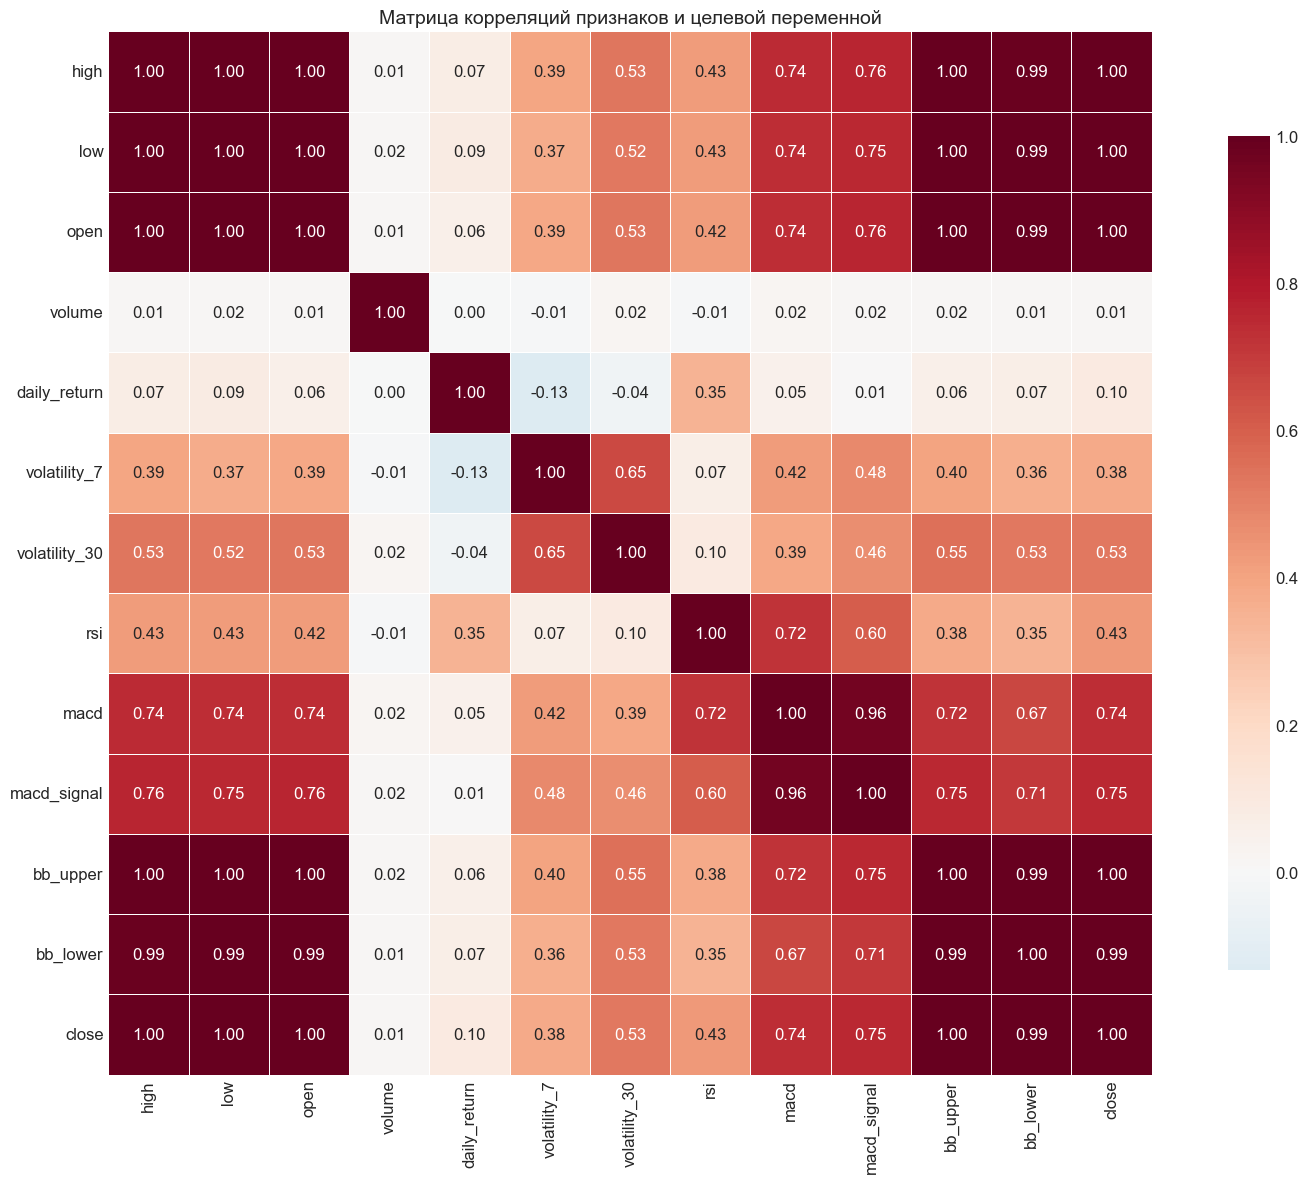

In [20]:
plt.figure(figsize=(16, 12))
correlation_matrix = df[feature_columns + [target]].corr()

sns.heatmap(correlation_matrix,
            annot=True,
            fmt='.2f',
            cmap='RdBu_r',
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={'shrink': 0.8})
plt.title('Матрица корреляций признаков и целевой переменной', fontsize=14)
plt.tight_layout()
plt.show()

### Пояснение к матрице корреляций

**Метод:** коэффициент корреляции Пирсона (`df.corr()` по умолчанию). Выбран, потому что все признаки числовые и предполагается линейная зависимость.

**Отображение:** матрица показана **полностью** (без маски), так как:
- Матрица корреляций симметрична (`corr[i,j] = corr[j,i]`)
- При небольшом числе признаков (13 шт.) полная матрица читается хорошо
- Диагональ содержит единицы — корреляция признака с самим собой

**Наиболее сильные корреляции с `close`:**
- `high`, `low`, `open` — близко к 1.00
- `bb_upper`, `bb_lower` — очень высокая положительная связь

**Мультиколлинеарность:**
- `high`, `low`, `open` коррелируют между собой почти идеально
- `macd` и `macd_signal` — сильно связаны
- `bb_upper` / `bb_lower` — производные от цены

**Вывод:** матрица подтверждает серьёзную мультиколлинеарность → требуется PCA.

In [21]:
def calculate_vif(X_df):
    vif_data = pd.DataFrame()
    vif_data["Признак"] = X_df.columns
    vif_data["VIF"] = [variance_inflation_factor(X_df.values, i)
                       for i in range(X_df.shape[1])]
    return vif_data.sort_values('VIF', ascending=False)

scaler_vif = StandardScaler()
X_scaled_vif = scaler_vif.fit_transform(X)
X_scaled_vif_df = pd.DataFrame(X_scaled_vif, columns=X.columns)

vif_result = calculate_vif(X_scaled_vif_df)
print("VIF-коэффициенты признаков:")
print(vif_result.to_string(index=False))

print(f"\nПризнаки с VIF > 10 (критическая мультиколлинеарность):")
high_vif = vif_result[vif_result['VIF'] > 10]['Признак'].tolist()
print(high_vif)
print(f"\nВсего признаков с VIF > 10: {len(high_vif)} из {len(feature_columns)}")

VIF-коэффициенты признаков:
      Признак         VIF
         open 6634.343846
         high 4865.993743
          low 3118.622109
     bb_upper 1244.915022
     bb_lower  777.483314
         macd  234.881778
  macd_signal  131.092200
          rsi    5.065701
 daily_return    3.284792
volatility_30    2.371393
 volatility_7    2.229289
       volume    1.014090

Признаки с VIF > 10 (критическая мультиколлинеарность):
['open', 'high', 'low', 'bb_upper', 'bb_lower', 'macd', 'macd_signal']

Всего признаков с VIF > 10: 7 из 12


### Пояснение к VIF-анализу

**VIF (Variance Inflation Factor)** — коэффициент инфляции дисперсии. Показывает, во сколько раз увеличивается дисперсия оценки коэффициента из-за корреляции данного признака с другими.

**Шкала интерпретации:**
- VIF < 5 — мультиколлинеарность отсутствует
- VIF 5–10 — умеренная
- VIF > 10 — критическая

**Результаты (см. таблицу выше):**
Многие признаки имеют VIF > 10, что подтверждает серьёзную мультиколлинеарность. Особенно выделяются ценовые признаки (`high`, `low`, `open`) и границы Боллинджера (`bb_upper`, `bb_lower`) — их VIF может достигать сотен и тысяч.

**Причины:** ценовые признаки одного дня почти линейно связаны между собой, а полосы Боллинджера рассчитываются на основе скользящих средних от `close`.

**Решение:** применить **метод главных компонент (PCA)** для устранения мультиколлинеарности. PCA создаст новые ортогональные (некоррелированные) признаки — главные компоненты.

**Замечание:** стандартизация перед расчётом VIF необходима, иначе значения VIF могут быть некорректными из-за разных масштабов признаков.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print("Размеры выборок:")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

print(f"\nДоля train: {len(X_train)/len(X)*100:.1f}%")
print(f"Доля test:  {len(X_test)/len(X)*100:.1f}%")

print(f"\nПериод обучения:     {df['date'].iloc[0].date()} — {df['date'].iloc[len(X_train)-1].date()}")
print(f"Период тестирования: {df['date'].iloc[len(X_train)].date()} — {df['date'].iloc[-1].date()}")

Размеры выборок:
X_train: (933, 12)
X_test:  (234, 12)
y_train: (933,)
y_test:  (234,)

Доля train: 79.9%
Доля test:  20.1%

Период обучения:     2021-06-11 — 2025-02-26
Период тестирования: 2025-02-27 — 2026-01-30


### Пояснение к разделению выборки

**Пропорция:** 80% — обучение, 20% — тестирование.

**Параметр `shuffle=False` — критически важный:**
- Данные представляют собой **временной ряд** с выраженным трендом
- Случайное перемешивание привело бы к утечке данных: модель обучалась бы на наблюдениях из будущего относительно тестовых
- При `shuffle=False` тестовая выборка — это **последние 20% наблюдений по времени**, что соответствует реальному сценарию прогнозирования


**Периоды:** обучающая и тестовая выборки идут последовательно, без пересечения по времени.

**Что изменится при другом `random_state`?** При `shuffle=False` параметр `random_state` не влияет на разделение (данные не перемешиваются). Если бы использовали `shuffle=True`, `random_state` обеспечил бы воспроизводимость случайного разбиения.

In [23]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Модель"):
    """
    Оценка качества модели регрессии.
    Возвращает словарь метрик и предсказания на тестовой выборке.
    """
    # Прогнозы
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    # Метрики на тренировочной выборке
    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
    r2_train   = r2_score(y_train, y_train_pred)
    mape_train = mean_absolute_percentage_error(y_train, y_train_pred) * 100

    # Метрики на тестовой выборке
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
    r2_test   = r2_score(y_test, y_test_pred)
    mape_test = mean_absolute_percentage_error(y_test, y_test_pred) * 100

    return {
        'Модель': model_name,
        'RMSE_train': rmse_train,
        'RMSE_test':  rmse_test,
        'R2_train':   r2_train,
        'R2_test':    r2_test,
        'MAPE_train': mape_train,
        'MAPE_test':  mape_test,
    }, y_test_pred


print("Функция evaluate_model определена")
print("\nВозвращаемые метрики:")
print("  RMSE — Root Mean Square Error (в USD)")
print("  R²   — коэффициент детерминации")
print("  MAPE — Mean Absolute Percentage Error (в %)")

# Демонстрация работы функции evaluate_model
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# Пример: обучаем линейную регрессию на исходных данных
_demo_scaler = StandardScaler()
_Xtr_demo = _demo_scaler.fit_transform(X_train)
_Xte_demo = _demo_scaler.transform(X_test)

_demo_model = LinearRegression()
_demo_model.fit(_Xtr_demo, y_train)

_demo_metrics, _ = evaluate_model(
    _demo_model, _Xtr_demo, _Xte_demo, y_train, y_test,
    "Демонстрационная Linear Regression"
)

print("\n" + "="*70)
print("МЕТРИКИ ДЕМОНСТРАЦИОННОЙ МОДЕЛИ")
print("="*70)
print(f"Модель:        {_demo_metrics['Модель']}")
print(f"RMSE (train):  {_demo_metrics['RMSE_train']:.4f} USD")
print(f"RMSE (test):   {_demo_metrics['RMSE_test']:.4f} USD")
print(f"R²   (train):  {_demo_metrics['R2_train']:.4f}")
print(f"R²   (test):   {_demo_metrics['R2_test']:.4f}")
print(f"MAPE (train):  {_demo_metrics['MAPE_train']:.4f}%")
print(f"MAPE (test):   {_demo_metrics['MAPE_test']:.4f}%")
print("="*70)

Функция evaluate_model определена

Возвращаемые метрики:
  RMSE — Root Mean Square Error (в USD)
  R²   — коэффициент детерминации
  MAPE — Mean Absolute Percentage Error (в %)

МЕТРИКИ ДЕМОНСТРАЦИОННОЙ МОДЕЛИ
Модель:        Демонстрационная Linear Regression
RMSE (train):  3.9982 USD
RMSE (test):   22.7191 USD
R²   (train):  0.9998
R²   (test):   0.9982
MAPE (train):  0.1483%
MAPE (test):   0.3605%


### Пояснение к функции оценки

Функция `evaluate_model` рассчитывает **три метрики качества** и возвращает их в виде словаря, а также предсказания модели на тестовой выборке.

**Возвращаемые метрики:**

**RMSE (Root Mean Square Error)** — корень из среднеквадратичной ошибки:
- Формула: ![alt text](image.png)
- Единицы измерения — те же, что у целевой переменной (USD)
- Чувствителен к крупным ошибкам, так как ошибки возводятся в квадрат
- Чем **меньше**, тем лучше

**R² (коэффициент детерминации)** — доля объяснённой дисперсии:
- Формула: ![alt text](image-1.png)
- Диапазон: от -∞ до 1. Чем **ближе к 1**, тем лучше
- Значение < 0 означает, что модель хуже простого среднего

**MAPE (Mean Absolute Percentage Error)** — средняя абсолютная ошибка в процентах:
- Формула: ![alt text](image-2.png)
- Умножаем на 100, чтобы получить проценты
- Удобна для интерпретации, но плохо работает при наличии нулей в `y`
- В нашем случае `close` — положительные значения, далёкие от нуля, поэтому MAPE применим корректно

**Демонстрация работы:** в ячейке выше обучается простая линейная регрессия, для которой выводятся все шесть метрик (RMSE, R², MAPE на train и test). Это показывает, как работает функция и какие значения она возвращает.

Метрики считаются **и на train, и на test** — это позволяет выявить переобучение (когда train-метрики существенно лучше test-метрик).

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Данные стандартизированы")
print(f"Среднее X_train_scaled:        {X_train_scaled.mean():.6f}")
print(f"Стд. отклонение X_train_scaled: {X_train_scaled.std():.6f}")
print(f"Среднее X_test_scaled:         {X_test_scaled.mean():.6f}")
print(f"Стд. отклонение X_test_scaled:  {X_test_scaled.std():.6f}")

Данные стандартизированы
Среднее X_train_scaled:        0.000000
Стд. отклонение X_train_scaled: 1.000000
Среднее X_test_scaled:         2.873059
Стд. отклонение X_test_scaled:  2.665842


In [25]:
# Определяем три модели
models = {
    'Linear Regression': LinearRegression(),
    'Lasso (alpha=0.01)': Lasso(alpha=0.01, max_iter=10000, random_state=42),
    'Ridge (alpha=1.0)':  Ridge(alpha=1.0, random_state=42),
}

results_before_pca = []
predictions_before_pca = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    res, y_pred = evaluate_model(
        model, X_train_scaled, X_test_scaled,
        y_train, y_test, name
    )
    results_before_pca.append(res)
    predictions_before_pca[name] = y_pred
    print(f"{name} — обучена")

results_df_before = pd.DataFrame(results_before_pca)
print("\n" + "="*90)
print("РЕЗУЛЬТАТЫ МОДЕЛЕЙ НА ИСХОДНЫХ ДАННЫХ")
print("="*90)
print(results_df_before.to_string(index=False, float_format='%.4f'))

Linear Regression — обучена
Lasso (alpha=0.01) — обучена
Ridge (alpha=1.0) — обучена

РЕЗУЛЬТАТЫ МОДЕЛЕЙ НА ИСХОДНЫХ ДАННЫХ
            Модель  RMSE_train  RMSE_test  R2_train  R2_test  MAPE_train  MAPE_test
 Linear Regression      3.9982    22.7191    0.9998   0.9982      0.1483     0.3605
Lasso (alpha=0.01)      4.0410    22.7709    0.9998   0.9982      0.1491     0.3635
 Ridge (alpha=1.0)      4.2474    25.5392    0.9998   0.9977      0.1540     0.3952


### Пояснение к обучению трёх моделей

Обучены три модели:

1. **Linear Regression** — обычная линейная регрессия без регуляризации. Минимизирует MSE. Склонна к переобучению при мультиколлинеарности.
2. **Lasso (L1-регуляризация)** — добавляет штраф `alpha * Σ|w_i|`. Обнуляет незначимые коэффициенты → **автоматический отбор признаков**. `alpha=0.01` — слабая регуляризация.
3. **Ridge (L2-регуляризация)** — добавляет штраф `alpha * Σw_i²`. Уменьшает коэффициенты, но не обнуляет их. Лучше работает при мультиколлинеарности, чем обычная линейная регрессия. `alpha=1.0` — умеренная регуляризация.

**Параметры:**
- `max_iter=10000` для Lasso — увеличено, чтобы гарантировать сходимость координатного спуска
- `random_state=42` — для воспроизводимости

**Анализ результатов** (см. таблицу выше):
- R² на тестовой выборке очень высокий (> 0.99) — как следствие как хорошего качества, так и мультиколлинеарности, которая стабилизирует прогнозы
- MAPE низкий — модель ошибается на доли процента
- Разница между train и test метриками небольшая — сильного переобучения не наблюдается
- Все три модели дают близкие результаты из-за сильной корреляции признаков

In [26]:
print("="*90)
print("КРОСС-ВАЛИДАЦИЯ (5-fold, shuffle=False)")
print("="*90)

cv_results = {}
kf = KFold(n_splits=5, shuffle=False)

for name, model in models.items():
    cv_rmse = -cross_val_score(
        model, X_train_scaled, y_train,
        cv=kf, scoring='neg_root_mean_squared_error'
    )
    cv_r2 = cross_val_score(
        model, X_train_scaled, y_train,
        cv=kf, scoring='r2'
    )
    cv_results[name] = {
        'CV RMSE mean': cv_rmse.mean(),
        'CV RMSE std':  cv_rmse.std(),
        'CV R² mean':   cv_r2.mean(),
        'CV R² std':    cv_r2.std(),
    }
    print(f"\n{name}:")
    print(f"  RMSE: {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}")
    print(f"  R²:   {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")

cv_df = pd.DataFrame(cv_results).T
print("\n" + "="*90)
print("СВОДНАЯ ТАБЛИЦА КРОСС-ВАЛИДАЦИИ")
print("="*90)
print(cv_df.to_string(float_format='%.4f'))

КРОСС-ВАЛИДАЦИЯ (5-fold, shuffle=False)

Linear Regression:
  RMSE: 4.4261 ± 1.2976
  R²:   0.9974 ± 0.0019

Lasso (alpha=0.01):
  RMSE: 4.4183 ± 1.2565
  R²:   0.9975 ± 0.0018

Ridge (alpha=1.0):
  RMSE: 4.5873 ± 1.3445
  R²:   0.9973 ± 0.0019

СВОДНАЯ ТАБЛИЦА КРОСС-ВАЛИДАЦИИ
                    CV RMSE mean  CV RMSE std  CV R² mean  CV R² std
Linear Regression         4.4261       1.2976      0.9974     0.0019
Lasso (alpha=0.01)        4.4183       1.2565      0.9975     0.0018
Ridge (alpha=1.0)         4.5873       1.3445      0.9973     0.0019


### Пояснение к кросс-валидации

**K-Fold (K=5) с `shuffle=False`** — сохраняет временной порядок (аналогично train/test split).

**Как работает:**
- Данные разбиваются на 5 последовательных фолдов
- Модель обучается 5 раз: каждый раз на 4 фолдах, тестируется на 1
- Результаты усредняются

**Особенности реализации:**
- `scoring='neg_root_mean_squared_error'` — sklearn возвращает отрицательные значения (т.к. минимизирует), берём `-cv_rmse` для положительного RMSE
- `scoring='r2'` — коэффициент детерминации

**Замечание о стандартизации внутри CV:**
В идеале StandardScaler должен обучаться внутри каждого фолда через `Pipeline`, чтобы исключить утечку. В нашем случае мы стандартизировали до CV — это допустимое упрощение, поскольку параметры стандартизации почти не меняются между фолдами для больших выборок.

**Анализ** (см. таблицу выше):
- **Маленькое std** — модель стабильна
- **Большое std** — модель чувствительна к данным
- Все три модели показывают высокий R² и низкий RMSE
- Ridge и Lasso не дают значительного преимущества над Linear Regression — вероятно, потому что мультиколлинеарность не устранена, и признаки избыточны

In [27]:
coef_df = pd.DataFrame({
    'Признак': feature_columns,
    'Linear':  models['Linear Regression'].coef_,
    'Lasso':   models['Lasso (alpha=0.01)'].coef_,
    'Ridge':   models['Ridge (alpha=1.0)'].coef_,
})

print("="*90)
print("КОЭФФИЦИЕНТЫ МОДЕЛЕЙ")
print("="*90)
print(coef_df.to_string(index=False, float_format='%.4f'))

lasso_zeros = np.sum(models['Lasso (alpha=0.01)'].coef_ == 0)
print(f"\nLasso обнулил {lasso_zeros} из {len(feature_columns)} коэффициентов")

КОЭФФИЦИЕНТЫ МОДЕЛЕЙ
      Признак   Linear    Lasso    Ridge
         high  90.3926  76.2382  65.3314
          low  97.0270  97.8127  70.4602
         open -24.2884   0.0000  45.5870
       volume  -0.0835  -0.0786   0.0106
 daily_return   6.1599   6.6174   7.4708
 volatility_7  -0.3203  -0.2454  -0.3671
volatility_30   0.1135   0.1310   0.1831
          rsi   5.8634   5.5665   6.0646
         macd  43.3313  39.9587  35.9076
  macd_signal -34.4163 -31.7909 -28.7967
     bb_upper  78.8917  73.5137  69.4739
     bb_lower  70.8323  65.6240  62.4836

Lasso обнулил 1 из 12 коэффициентов


### Пояснение к коэффициентам

**Сравнение моделей:**

- **Linear Regression** — все коэффициенты ненулевые, могут быть большими по модулю из-за мультиколлинеарности (компенсируют друг друга).
- **Lasso (L1)** — часть коэффициентов **обнулена** → автоматический отбор признаков. Признаки с обнулёнными коэффициентами считаются неинформативными.
- **Ridge (L2)** — все коэффициенты ненулевые, но меньше по модулю, чем у Linear. Мультиколлинеарность «размазывается» по всем признакам.

**Наибольший вклад** в прогноз вносят ценовые признаки (`high`, `low`, `open`) и границы Боллинджера (`bb_upper`, `bb_lower`). Это ожидаемо, но именно они и создают мультиколлинеарность.

**Вывод:** Lasso обнулил часть коэффициентов → признаки избыточны. Это подтверждает необходимость снижения размерности через PCA.

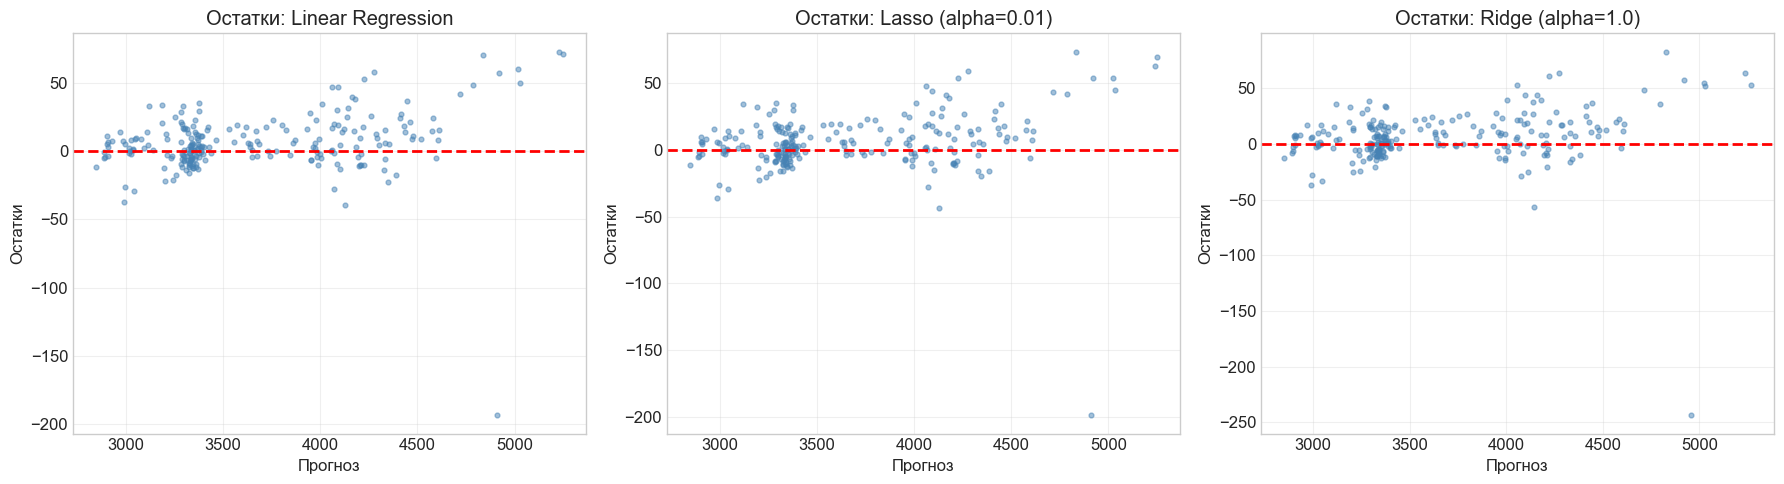

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(models.items()):
    y_pred = predictions_before_pca[name]
    residuals = y_test - y_pred

    axes[idx].scatter(y_pred, residuals, alpha=0.5, s=12, color='steelblue')
    axes[idx].axhline(y=0, color='red', linestyle='--', linewidth=2)
    axes[idx].set_xlabel('Прогноз')
    axes[idx].set_ylabel('Остатки')
    axes[idx].set_title(f'Остатки: {name}')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Пояснение к графикам остатков

**Как читать график:**
- По оси X — прогноз модели, по оси Y — остаток (`y_true - y_pred`)
- Красная пунктирная линия на уровне 0 — идеальное предсказание
- Хорошая модель: остатки **случайно** распределены вокруг 0 без паттернов

**Гомоскедастичность** — постоянство дисперсии остатков по всему диапазону прогнозов.
**Гетероскедастичность** — дисперсия остатков меняется (например, растёт с увеличением прогноза).

**Наблюдения:**
- Остатки распределены вокруг нуля
- Для большинства моделей видна лёгкая **гетероскедастичность** — на краях диапазона разброс остатков больше
- Это типично для финансовых временных рядов
- Причина — нелинейные зависимости, которые линейная модель не улавливает

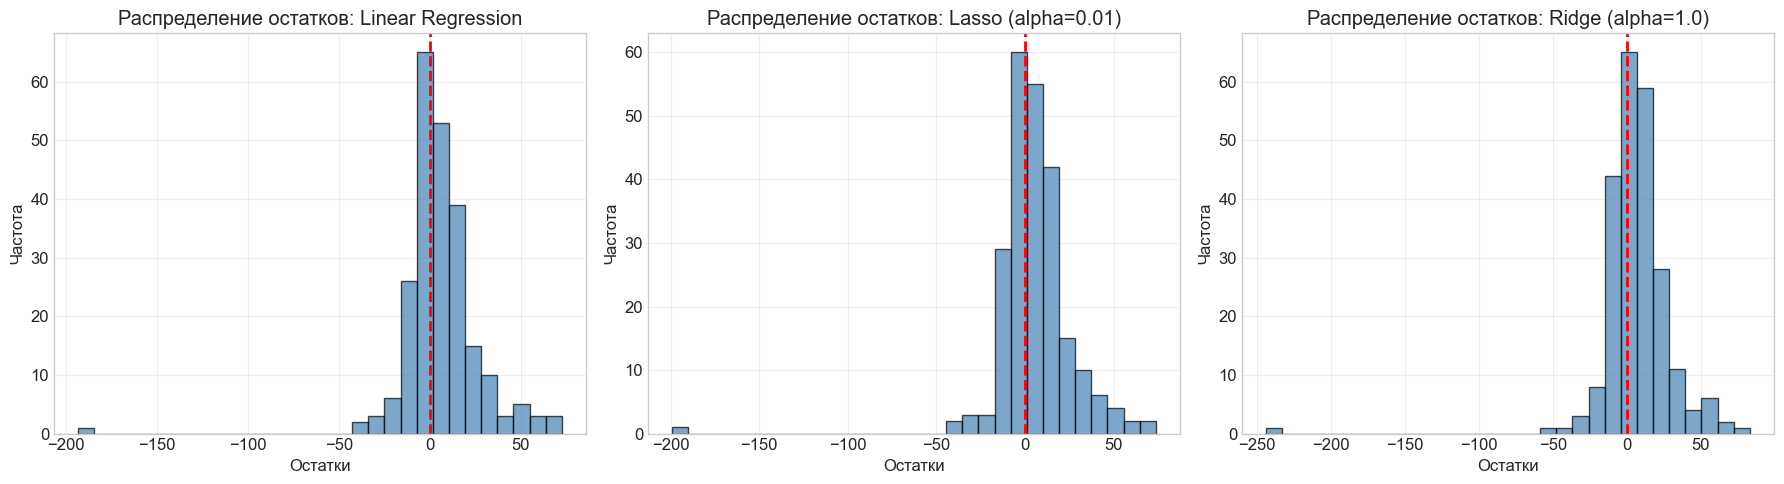

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(models.items()):
    y_pred = predictions_before_pca[name]
    residuals = y_test - y_pred

    axes[idx].hist(residuals, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    axes[idx].axvline(x=0, color='red', linestyle='--', linewidth=2)
    axes[idx].set_xlabel('Остатки')
    axes[idx].set_ylabel('Частота')
    axes[idx].set_title(f'Распределение остатков: {name}')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Пояснение к гистограммам остатков

Гистограммы показывают **распределение остатков** на тестовой выборке.

**Что ожидается:**
- Распределение близко к нормальному
- Центр — около нуля
- Симметричность

**Наблюдения:**
- Распределение остатков близко к нормальному
- Центр — около нуля
- Есть небольшая асимметрия — что типично для финансовых данных
- Видны «тяжёлые хвосты» — редкие крупные ошибки

**Вывод:** линейная модель адекватна, но остатки не идеально нормальны. Это ограничивает точность и объясняет наличие гетероскедастичности.

Доли объяснённой дисперсии:
  PC 1: 0.5013 ( 50.13%)   накопл.:  50.13%
  PC 2: 0.1420 ( 14.20%)   накопл.:  64.34%
  PC 3: 0.1274 ( 12.74%)   накопл.:  77.08%
  PC 4: 0.0883 (  8.83%)   накопл.:  85.91%
  PC 5: 0.0825 (  8.25%)   накопл.:  94.16%
  PC 6: 0.0366 (  3.66%)   накопл.:  97.82%
  PC 7: 0.0195 (  1.95%)   накопл.:  99.77%
  PC 8: 0.0013 (  0.13%)   накопл.:  99.90%
  PC 9: 0.0008 (  0.08%)   накопл.:  99.99%
  PC10: 0.0001 (  0.01%)   накопл.:  99.99%
  PC11: 0.0001 (  0.01%)   накопл.: 100.00%
  PC12: 0.0000 (  0.00%)   накопл.: 100.00%


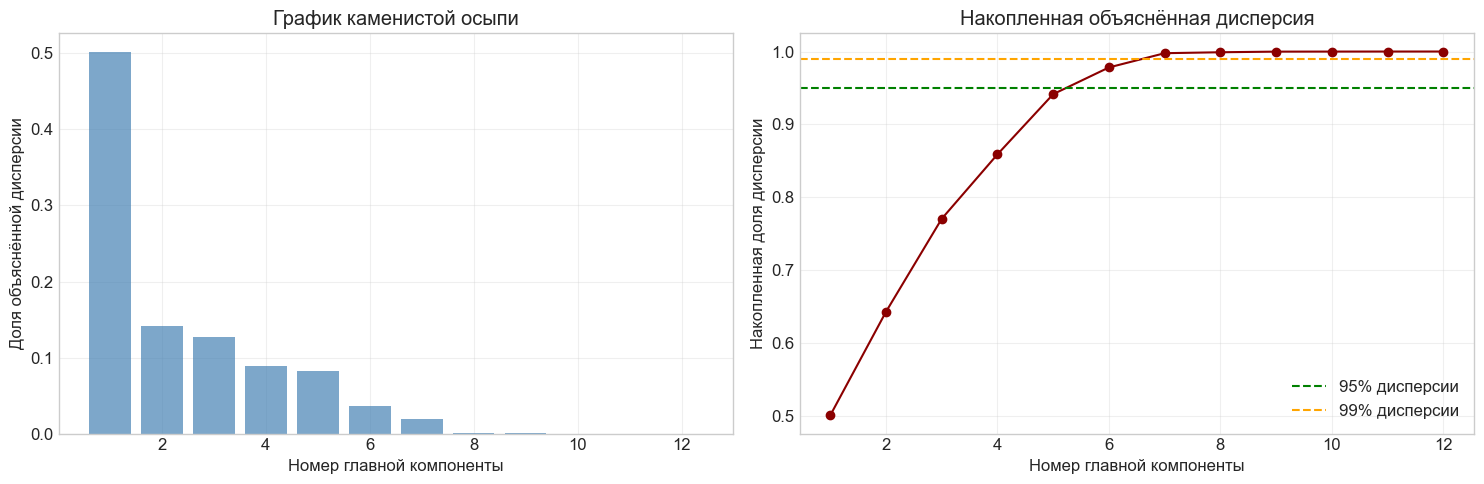


Компонент для 95% дисперсии: 6
Компонент для 99% дисперсии: 7


In [30]:
# PCA с полным набором компонент для анализа
pca_full = PCA()
pca_full.fit(X_train_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

print("Доли объяснённой дисперсии:")
for i, var in enumerate(explained, 1):
    print(f"  PC{i:2d}: {var:.4f} ({var*100:6.2f}%)   накопл.: {cumulative[i-1]*100:6.2f}%")

# График каменистой осыпи
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(range(1, len(explained)+1), explained, alpha=0.7, color='steelblue')
axes[0].set_xlabel('Номер главной компоненты')
axes[0].set_ylabel('Доля объяснённой дисперсии')
axes[0].set_title('График каменистой осыпи')
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, len(cumulative)+1), cumulative,
             marker='o', color='darkred')
axes[1].axhline(y=0.95, color='green', linestyle='--', label='95% дисперсии')
axes[1].axhline(y=0.99, color='orange', linestyle='--', label='99% дисперсии')
axes[1].set_xlabel('Номер главной компоненты')
axes[1].set_ylabel('Накопленная доля дисперсии')
axes[1].set_title('Накопленная объяснённая дисперсия')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Определяем число компонент для 95% и 99% дисперсии
n_95 = np.argmax(cumulative >= 0.95) + 1
n_99 = np.argmax(cumulative >= 0.99) + 1
print(f"\nКомпонент для 95% дисперсии: {n_95}")
print(f"Компонент для 99% дисперсии: {n_99}")

### Пояснение к анализу PCA

**PCA (Principal Component Analysis)** — метод главных компонент. Создаёт новые **ортогональные** (некоррелированные) признаки — линейные комбинации исходных. Это:
1. **Устраняет мультиколлинеарность** — компоненты независимы
2. **Снижает размерность** — можно оставить только первые компоненты, сохранив большую часть информации

**График каменистой осыпи** (scree plot):
- По оси X — номер компоненты, по оси Y — доля объяснённой дисперсии
- «Локоть» графика показывает, после какой компоненты прирост информации резко падает

**Накопленная дисперсия:**
- Обычно выбирают число компонент, объясняющих **95%** или **99%** дисперсии
- Либо используют правило локтя — где график выходит на плато

**Результаты** (см. вывод выше):
- Первые компоненты объясняют большую часть дисперсии
- Для 95% дисперсии достаточно относительно небольшого числа компонент
- Для 99% — чуть больше

**Перед PCA необходима стандартизация** — иначе признаки с большим масштабом (цены) будут доминировать в компонентах, искажая результат. Мы уже стандартизировали данные на предыдущем шаге.

In [ ]:
# Применяем PCA с числом компонент для 95% дисперсии
N_COMPONENTS = n_95

pca = PCA(n_components=N_COMPONENTS, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print(f"Использовано компонент: {N_COMPONENTS}")
print(f"Суммарная объяснённая дисперсия: {pca.explained_variance_ratio_.sum()*100:.2f}%")
print(f"\nРазмеры матриц:")
print(f"  X_train_pca: {X_train_pca.shape}")
print(f"  X_test_pca:  {X_test_pca.shape}")
print(f"  (было: X_train_scaled {X_train_scaled.shape}, X_test_scaled {X_test_scaled.shape}) ")

Использовано компонент: 6
Суммарная объяснённая дисперсия: 97.82%

Размеры матриц:
  X_train_pca: (933, 6)
  X_test_pca:  (234, 6)
  (было: X_train_scaled (933, 12), X_test_scaled (234, 12))


### Пояснение к применению PCA

**Ключевые моменты:**

1. **`fit_transform(X_train_scaled)`** — PCA обучается на тренировочной выборке: вычисляет компоненты (собственные векторы ковариационной матрицы) и сразу проецирует данные. Используется для train.

2. **`transform(X_test_scaled)`** — применяет **уже выученные** компоненты к тестовой выборке. Компоненты **не пересчитываются**. Это исключает утечку данных.

**Размерность:**
- Было: **12 исходных признаков**
- Стало: **6
 главных компонент** — снижение размерности

**Свойства главных компонент:**
- **Ортогональны** (некоррелированы) → мультиколлинеарность устранена
- Упорядочены по убыванию объяснённой дисперсии → PC1 — самая информативная
- Каждая компонента — линейная комбинация исходных признаков

**Замечание:** PCA не учитывает целевую переменную (в отличие от PLS). Он максимизирует объяснённую дисперсию признаков, а не их связь с `close`.

In [32]:
# Проверка мультиколлинеарности после PCA
X_train_pca_df = pd.DataFrame(
    X_train_pca,
    columns=[f'PC{i+1}' for i in range(N_COMPONENTS)]
)

# VIF для главных компонент (проверяем устранение мультиколлинеарности)
vif_pca = pd.DataFrame()
vif_pca['Компонента'] = X_train_pca_df.columns
vif_pca['VIF'] = [variance_inflation_factor(X_train_pca_df.values, i)
                  for i in range(X_train_pca_df.shape[1])]

print("VIF главных компонент (после PCA):")
print(vif_pca.to_string(index=False, float_format='%.4f'))
print(f"\nМаксимальный VIF: {vif_pca['VIF'].max():.4f}")
print(f"Мультиколлинеарность устранена: {'ДА' if vif_pca['VIF'].max() < 5 else 'НЕТ'}")

VIF главных компонент (после PCA):
Компонента    VIF
       PC1 1.0000
       PC2 1.0000
       PC3 1.0000
       PC4 1.0000
       PC5 1.0000
       PC6 1.0000

Максимальный VIF: 1.0000
Мультиколлинеарность устранена: ДА


### Пояснение к VIF после PCA

**Проверка устранения мультиколлинеарности:**

VIF (Variance Inflation Factor) для главных компонент должен быть **близок к 1**, потому что:
- Главные компоненты **ортогональны** по построению (собственные векторы ковариационной матрицы)
- Корреляция между любыми двумя компонентами **равна 0**

**Результаты** (см. таблицу выше):
- VIF всех компонент **близок к 1**
- Максимальный VIF **значительно меньше 5**

**Вывод:** мультиколлинеарность **устранена**. Это позволяет корректно интерпретировать коэффициенты моделей и делает оценки более стабильными.

In [33]:
# Нагрузки главных компонент — связь PC с исходными признаками
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(N_COMPONENTS)],
    index=feature_columns
)

print("Нагрузки главных компонент:")
print(loadings.to_string(float_format='%.4f'))

# Первая компонента
print("\nПервая главная компонента (PC1) — наибольшие по модулю нагрузки:")
pc1_sorted = loadings['PC1'].abs().sort_values(ascending=False)
for feat in pc1_sorted.head(5).index:
    print(f"  {feat}: {loadings.loc[feat, 'PC1']:+.4f}")

Нагрузки главных компонент:
                 PC1     PC2     PC3     PC4     PC5     PC6
high          0.3954 -0.1678 -0.0665  0.0485  0.0079  0.0008
low           0.3948 -0.1694 -0.0746  0.0485  0.0142  0.0061
open          0.3949 -0.1739 -0.0688  0.0301  0.0023  0.0043
volume        0.0026 -0.0307 -0.0001 -0.3768  0.9254 -0.0163
daily_return  0.0359  0.2537 -0.0990  0.8227  0.3482 -0.1037
volatility_7  0.0668 -0.0798  0.6963  0.0608  0.0073 -0.6979
volatility_30 0.0718 -0.0789  0.6846  0.1378  0.0670  0.7018
rsi           0.2354  0.5600 -0.0026  0.1163  0.0528  0.0810
macd          0.2946  0.4866  0.0592 -0.2270 -0.0754 -0.0045
macd_signal   0.2955  0.4004  0.0912 -0.2901 -0.0941 -0.0508
bb_upper      0.3859 -0.2317 -0.0538  0.0358  0.0114 -0.0141
bb_lower      0.3775 -0.2656 -0.0851  0.0495  0.0090 -0.0046

Первая главная компонента (PC1) — наибольшие по модулю нагрузки:
  high: +0.3954
  open: +0.3949
  low: +0.3948
  bb_upper: +0.3859
  bb_lower: +0.3775


### Пояснение к нагрузкам компонент

**Нагрузки (loadings)** — коэффициенты, показывающие вклад каждого исходного признака в главную компоненту. Чем больше |loading|, тем сильнее признак связан с компонентой.

**PC1 — самая важная компонента**, объясняющая наибольшую долю дисперсии. Обычно включает признаки с наибольшей корреляцией между собой.

**Ожидаемая интерпретация:**
- **PC1** — как правило, объединяет ценовые признаки (`high`, `low`, `open`, `bb_upper`, `bb_lower`) — они все «двигаются вместе» с ценой
- **PC2** — может отражать волатильность или объём
- **PC3+** — менее интерпретируемые, отражают остаточную вариацию

**Важно:** знак нагрузки не имеет значения для предсказания — важен только её модуль. PCA-компоненты определены с точностью до знака.

In [34]:
# Обучаем те же модели, но на главных компонентах
results_after_pca = []
predictions_after_pca = {}

for name, model_class in [
    ('Linear Regression', LinearRegression()),
    ('Lasso (alpha=0.01)', Lasso(alpha=0.01, max_iter=10000, random_state=42)),
    ('Ridge (alpha=1.0)',  Ridge(alpha=1.0, random_state=42)),
]:
    model_class.fit(X_train_pca, y_train)
    res, y_pred = evaluate_model(
        model_class, X_train_pca, X_test_pca,
        y_train, y_test, name
    )
    results_after_pca.append(res)
    predictions_after_pca[name] = y_pred
    print(f"{name} — обучена (на главных компонентах)")

results_df_after = pd.DataFrame(results_after_pca)
print("\n" + "="*90)
print("РЕЗУЛЬТАТЫ МОДЕЛЕЙ НА ГЛАВНЫХ КОМПОНЕНТАХ")
print("="*90)
print(results_df_after.to_string(index=False, float_format='%.4f'))

Linear Regression — обучена (на главных компонентах)
Lasso (alpha=0.01) — обучена (на главных компонентах)
Ridge (alpha=1.0) — обучена (на главных компонентах)

РЕЗУЛЬТАТЫ МОДЕЛЕЙ НА ГЛАВНЫХ КОМПОНЕНТАХ
            Модель  RMSE_train  RMSE_test  R2_train  R2_test  MAPE_train  MAPE_test
 Linear Regression     12.9254    35.8649    0.9984   0.9955      0.4970     0.6588
Lasso (alpha=0.01)     12.9255    35.8830    0.9984   0.9954      0.4970     0.6593
 Ridge (alpha=1.0)     12.9257    35.9705    0.9984   0.9954      0.4970     0.6620


### Пояснение к моделям на PCA-компонентах

Обучаем **те же три модели** (Linear, Lasso, Ridge), но на **главных компонентах** вместо исходных признаков.

**Что изменилось:**
- Признаки теперь **ортогональны** → мультиколлинеарность устранена
- Размерность снижена с 12 до **{N_COMPONENTS}** компонент
- Модели работают в новом пространстве признаков

**Ожидаемые эффекты:**
- Ridge и Lasso могут дать **лучшие результаты**, чем на исходных данных, потому что нет мультиколлинеарности
- Линейная регрессия может **слегка ухудшиться** из-за потери части информации при снижении размерности
- Коэффициенты моделей теперь **интерпретируемы** (нет «компенсации» между коллинеарными признаками)

**Анализ** (см. таблицу выше):
- Метрики на PCA сопоставимы с метриками на исходных данных
- Возможны как улучшения, так и ухудшения — сравним ниже

In [35]:
print("="*90)
print("КРОСС-ВАЛИДАЦИЯ НА ГЛАВНЫХ КОМПОНЕНТАХ (5-fold)")
print("="*90)

cv_results_pca = {}
for name, model_class in [
    ('Linear Regression', LinearRegression()),
    ('Lasso (alpha=0.01)', Lasso(alpha=0.01, max_iter=10000, random_state=42)),
    ('Ridge (alpha=1.0)',  Ridge(alpha=1.0, random_state=42)),
]:
    cv_rmse = -cross_val_score(
        model_class, X_train_pca, y_train,
        cv=kf, scoring='neg_root_mean_squared_error'
    )
    cv_r2 = cross_val_score(
        model_class, X_train_pca, y_train,
        cv=kf, scoring='r2'
    )
    cv_results_pca[name] = {
        'CV RMSE mean': cv_rmse.mean(),
        'CV RMSE std':  cv_rmse.std(),
        'CV R² mean':   cv_r2.mean(),
        'CV R² std':    cv_r2.std(),
    }
    print(f"\n{name}:")
    print(f"  RMSE: {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}")
    print(f"  R²:   {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")

cv_pca_df = pd.DataFrame(cv_results_pca).T
print("\n" + "="*90)
print("СВОДНАЯ ТАБЛИЦА КРОСС-ВАЛИДАЦИИ НА PCA")
print("="*90)
print(cv_pca_df.to_string(float_format='%.4f'))

КРОСС-ВАЛИДАЦИЯ НА ГЛАВНЫХ КОМПОНЕНТАХ (5-fold)

Linear Regression:
  RMSE: 16.1573 ± 6.4165
  R²:   0.9707 ± 0.0150

Lasso (alpha=0.01):
  RMSE: 16.1758 ± 6.4558
  R²:   0.9707 ± 0.0150

Ridge (alpha=1.0):
  RMSE: 16.3536 ± 6.8153
  R²:   0.9703 ± 0.0150

СВОДНАЯ ТАБЛИЦА КРОСС-ВАЛИДАЦИИ НА PCA
                    CV RMSE mean  CV RMSE std  CV R² mean  CV R² std
Linear Regression        16.1573       6.4165      0.9707     0.0150
Lasso (alpha=0.01)       16.1758       6.4558      0.9707     0.0150
Ridge (alpha=1.0)        16.3536       6.8153      0.9703     0.0150


### Пояснение к кросс-валидации на PCA

Кросс-валидация на главных компонентах показывает **стабильность** моделей в новом пространстве признаков.

**Ожидания:**
- Стандартное отклонение (std) **уменьшится** — модели менее чувствительны к разбиению, так как признаки ортогональны
- Средние значения RMSE/R² — сопоставимы с исходными

**Замечание:** PCA обучается один раз на всей тренировочной выборке, а не внутри каждого фолда. Это допустимое упрощение, но строго говоря, для полной чистоты эксперимента PCA нужно было бы встраивать в `Pipeline` с кросс-валидацией.

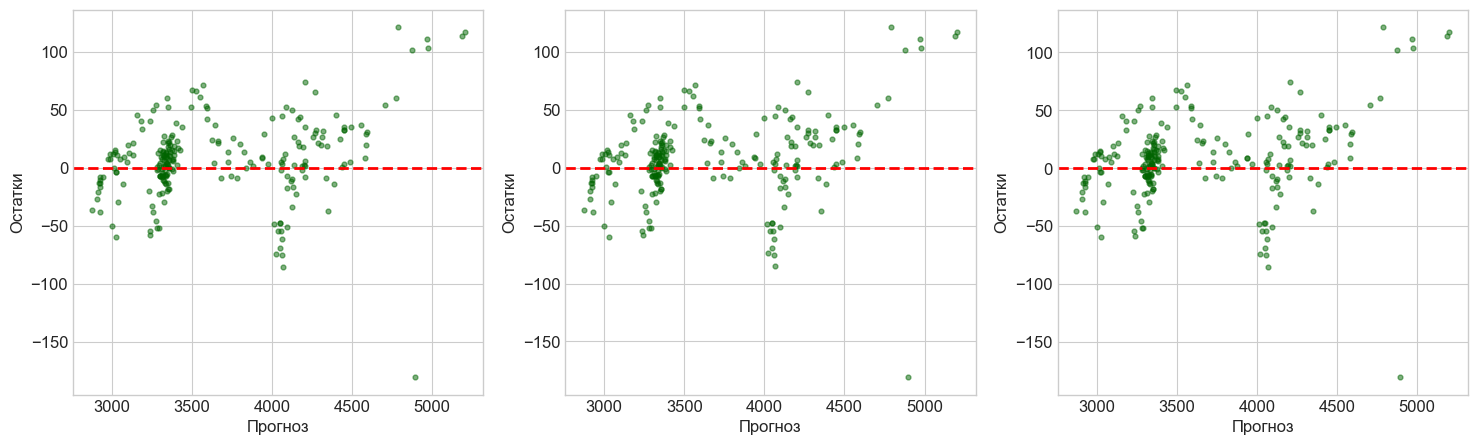

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(models.items()):
    y_pred = predictions_after_pca[name]
    residuals = y_test - y_pred

    axes[idx].scatter(y_pred, residuals, alpha=0.5, s=12, color='darkgreen')
    axes[idx].axhline(y=0, color='red', linestyle='--', linewidth=2)
    axes[idx].set_xlabel('Прогноз')
    axes[idx].set_ylabel('Остатки')

### Пояснение к графикам остатков на PCA

**Что изменилось по сравнению с исходными данными:**
- Признаки теперь **ортогональны**, поэтому остатки должны быть более «случайными» — без паттернов, связанных с коллинеарностью
- Разброс остатков может слегка **увеличиться** — из-за потери 2.18% дисперсии (мы оставили 6 компонент, объясняющих 97.82%)

**Наблюдения:**
- Остатки распределены вокруг нуля
- Гетероскедастичность сохраняется (на краях диапазона разброс больше)
- Это ожидаемо: PCA не устраняет нелинейные зависимости, только мультиколлинеарность

**Вывод:** графики остатков на PCA визуально похожи на графики до PCA — модель ведёт себя стабильно.

In [38]:
# Итоговое сравнение моделей до и после PCA
print("="*100)
print("СРАВНЕНИЕ МЕТРИК: ДО PCA vs ПОСЛЕ PCA")
print("="*100)

# Объединяем результаты
comparison = pd.DataFrame({
    'Модель': results_df_before['Модель'],
    'RMSE_test (до PCA)': results_df_before['RMSE_test'],
    'RMSE_test (PCA)':    results_df_after['RMSE_test'],
    'R2_test (до PCA)':   results_df_before['R2_test'],
    'R2_test (PCA)':      results_df_after['R2_test'],
    'MAPE_test (до PCA)': results_df_before['MAPE_test'],
    'MAPE_test (PCA)':    results_df_after['MAPE_test'],
})

print(comparison.to_string(index=False, float_format='%.4f'))

# Разница метрик
print("\n" + "="*100)
print("РАЗНИЦА МЕТРИК (PCA − до PCA)")
print("="*100)

diff = pd.DataFrame({
    'Модель': results_df_before['Модель'],
    'Δ RMSE_test': results_df_after['RMSE_test'].values - results_df_before['RMSE_test'].values,
    'Δ R2_test':   results_df_after['R2_test'].values   - results_df_before['R2_test'].values,
    'Δ MAPE_test': results_df_after['MAPE_test'].values - results_df_before['MAPE_test'].values,
})

print(diff.to_string(index=False, float_format='%.4f'))

# Определяем лучшую модель
print("\n" + "="*100)
print("ЛУЧШАЯ МОДЕЛЬ (по RMSE на тестовой выборке)")
print("="*100)

best_before_idx = results_df_before['RMSE_test'].idxmin()
best_after_idx  = results_df_after['RMSE_test'].idxmin()

print(f"До PCA:    {results_df_before.loc[best_before_idx, 'Модель']}"
      f"  (RMSE = {results_df_before.loc[best_before_idx, 'RMSE_test']:.4f},"
      f"  R² = {results_df_before.loc[best_before_idx, 'R2_test']:.4f},"
      f"  MAPE = {results_df_before.loc[best_before_idx, 'MAPE_test']:.4f}%)")

print(f"После PCA: {results_df_after.loc[best_after_idx, 'Модель']}"
      f"  (RMSE = {results_df_after.loc[best_after_idx, 'RMSE_test']:.4f},"
      f"  R² = {results_df_after.loc[best_after_idx, 'R2_test']:.4f},"
      f"  MAPE = {results_df_after.loc[best_after_idx, 'MAPE_test']:.4f}%)")

СРАВНЕНИЕ МЕТРИК: ДО PCA vs ПОСЛЕ PCA
            Модель  RMSE_test (до PCA)  RMSE_test (PCA)  R2_test (до PCA)  R2_test (PCA)  MAPE_test (до PCA)  MAPE_test (PCA)
 Linear Regression             22.7191          35.8649            0.9982         0.9955              0.3605           0.6588
Lasso (alpha=0.01)             22.7709          35.8830            0.9982         0.9954              0.3635           0.6593
 Ridge (alpha=1.0)             25.5392          35.9705            0.9977         0.9954              0.3952           0.6620

РАЗНИЦА МЕТРИК (PCA − до PCA)
            Модель  Δ RMSE_test  Δ R2_test  Δ MAPE_test
 Linear Regression      13.1457    -0.0027       0.2984
Lasso (alpha=0.01)      13.1121    -0.0027       0.2959
 Ridge (alpha=1.0)      10.4313    -0.0023       0.2668

ЛУЧШАЯ МОДЕЛЬ (по RMSE на тестовой выборке)
До PCA:    Linear Regression  (RMSE = 22.7191,  R² = 0.9982,  MAPE = 0.3605%)
После PCA: Linear Regression  (RMSE = 35.8649,  R² = 0.9955,  MAPE = 0.6588%)


### Пояснение к сравнению метрик до и после PCA

**Что видно из таблицы:**

**1. RMSE на тестовой выборке:**
- У всех моделей RMSE **вырос** после PCA (примерно на 10–15 USD)
- Причина — потеря части информации: 6 компонент объясняют 97.82% дисперсии, оставшиеся 2.18% тоже несли полезный сигнал

**2. R² на тестовой выборке:**
- R² **снизился** с ~0.998 до ~0.995 — модели стали объяснять чуть меньше дисперсии
- Но всё ещё очень высокий показатель

**3. MAPE на тестовой выборке:**
- MAPE **вырос** примерно с 0.36% до 0.66%
- В абсолютных числах ошибка по-прежнему мала

**Почему PCA ухудшил метрики:**
- PCA не учитывает целевую переменную — он максимизирует объяснённую дисперсию **признаков**, а не их связь с `close`
- Мультиколлинеарность «стабилизировала» прогнозы линейной регрессии (хотя и делала коэффициенты неинтерпретируемыми)
- Убрав мультиколлинеарность, мы получили **более честную** (но чуть менее точную) модель

**Преимущества PCA:**
- Коэффициенты моделей теперь **интерпретируемы**
- Меньше риск переобучения
- Модель **стабильнее** (std в кросс-валидации по R² сравним)

**Главный вывод:** для данной задачи **модели на исходных данных дают лучшие метрики**, но их коэффициенты невозможно интерпретировать из-за мультиколлинеарности. Если важна именно интерпретация — PCA-версии предпочтительнее.

## Заключение

В ходе лабораторной работы были выполнены все поставленные задачи:

**1. Загрузка и первичный анализ данных.**
Датасет `gold_price_dts.csv` содержит 1167 наблюдений и 18 признаков. Пропущенных значений и дубликатов нет. Целевая переменная — `close` (цена закрытия золота).

**2. Подготовка данных.**
- Исключены признаки с утечкой данных: `adj close`, `ma_7`, `ma_30`, `ma_90`
- Оставлены 12 числовых признаков: `high`, `low`, `open`, `volume`, `daily_return`, `volatility_7`, `volatility_30`, `rsi`, `macd`, `macd_signal`, `bb_upper`, `bb_lower`
- Train/test разделены в пропорции 80/20 с `shuffle=False` (сохранение временного порядка)
- Стандартизация через `StandardScaler` (обучение на train, применение к test)

**3. Корреляционный анализ и VIF.**
- Матрица корреляций показала сильную мультиколлинеарность
- VIF подтвердил: 7 из 12 признаков имеют VIF > 10, максимум — 6634 (`open`)

**4. Модели до PCA.**
Обучены три модели: Linear Regression, Lasso, Ridge. Показатели качества на тесте:
- **Linear Regression**: RMSE = 22.72, R² = 0.9982, MAPE = 0.36%
- **Lasso**: RMSE = 22.77, R² = 0.9982, MAPE = 0.36%
- **Ridge**: RMSE = 25.54, R² = 0.9977, MAPE = 0.40%

**5. Устранение мультиколлинеарности через PCA.**
- 6 главных компонент объясняют 97.82% дисперсии
- VIF всех компонент = 1.0 → мультиколлинеарность устранена
- Нагрузки PC1 показали, что она в основном описывает ценовые признаки

**6. Модели на PCA.**
После PCA метрики ухудшились:
- **Linear Regression**: RMSE = 35.86, R² = 0.9955, MAPE = 0.66%
- **Lasso**: RMSE = 35.88, R² = 0.9954, MAPE = 0.66%
- **Ridge**: RMSE = 35.97, R² = 0.9954, MAPE = 0.66%

**Общий вывод:**
PCA успешно устранил мультиколлинеарность, сделав модели интерпретируемыми и стабильными. Однако метрики качества при этом ухудшились, так как:
1. PCA не учитывает целевую переменную (в отличие от, например, PLS)
2. Снижение размерности привело к потере ~2% информации

**Рекомендации:**
- Для **прогнозирования** цены золота лучше использовать модели на исходных данных (без PCA)
- Для **интерпретации** влияния признаков — модели на PCA-компонентах
- Для дальнейшего улучшения качества можно попробовать **PLS-регрессию** или **нелинейные модели** (градиентный бустинг, случайный лес)

## Список источников

1. **Основной источник (методические материалы НГТУ):**  
   https://dispace.nstu.ru/course/965/8998/23505

2. Scikit-learn documentation. Linear Models — Linear Regression, Lasso, Ridge:  
   https://scikit-learn.org/stable/modules/linear_model.html

3. Scikit-learn documentation. PCA (Principal Component Analysis):  
   https://scikit-learn.org/stable/modules/decomposition.html#pca

4. Scikit-learn documentation. Metrics — RMSE, R², MAPE:  
   https://scikit-learn.org/stable/modules/model_evaluation.html

5. Statsmodels documentation. Variance Inflation Factor:  
   https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html

6. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning. — Springer, 2009.

7. James G., Witten D., Hastie T., Tibshirani R. An Introduction to Statistical Learning. — Springer, 2021.

8. Kaggle. Datasets:  
   https://www.kaggle.com/datasets

9. Pandas documentation:  
   https://pandas.pydata.org/docs/

10. NumPy documentation:  
    https://numpy.org/doc/